### Categorical Plots
Disclaimer: I will use figure level functions only if they exist for a specific graph

#### Categorical Scatter Plots
- Stripplot
- Swarmplot

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [24]:
tips=sns.load_dataset('tips')
iris=sns.load_dataset('iris')

#### Stripplot (for numerical vs categorical)

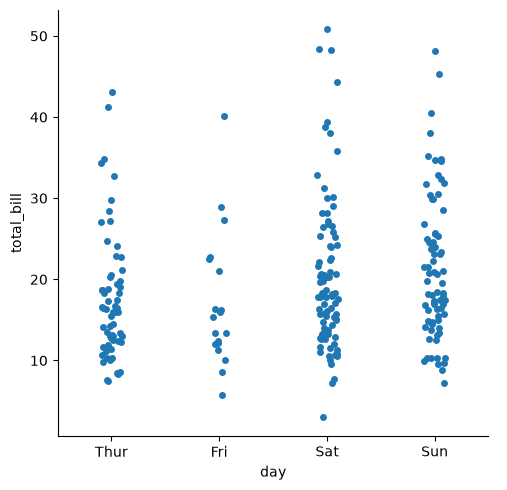

In [25]:
sns.catplot(data=tips,y='total_bill',x='day',kind='strip')

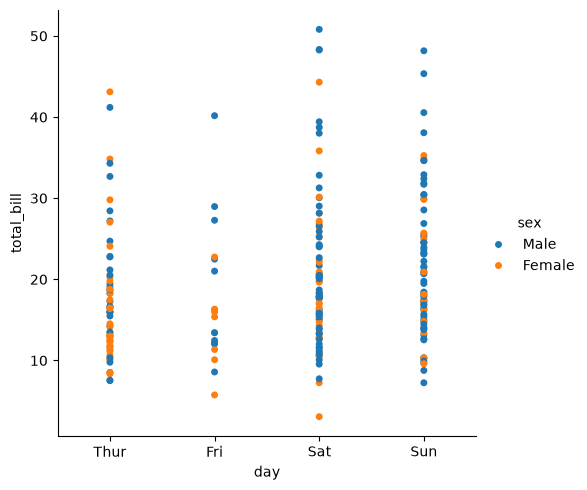

In [26]:
sns.catplot(data=tips,y='total_bill',x='day',kind='strip',jitter=False,hue='sex') #jitter=False will remove the noise which seaborn added for better visuals

#### Swarmplot is brother of stripplot, it just gives better distribution of data

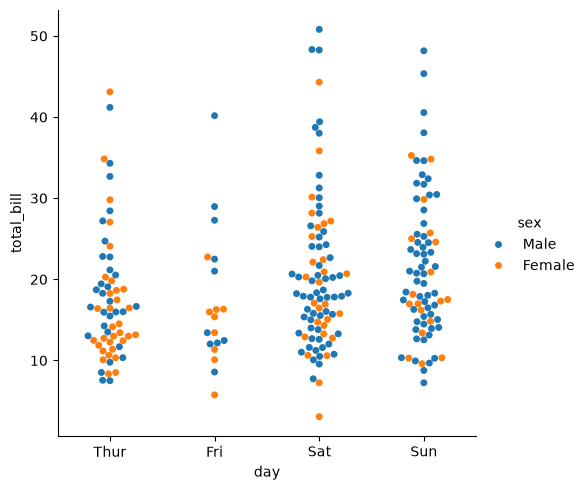

In [27]:
sns.catplot(data=tips,x='day',y='total_bill',kind='swarm',hue='sex')

#### Cartegorical Distribution Plots
- Boxplot
- Violinplot

### Boxplot

A boxplot is a standardized way of displaying the distribution of data based on a five number summary (“minimum”, first quartile [Q1], median, third quartile [Q3] and “maximum”). It can tell you about your outliers and what their values are. Boxplots can also tell you if your data is symmetrical, how tightly your data is grouped and if and how your data is skewed.

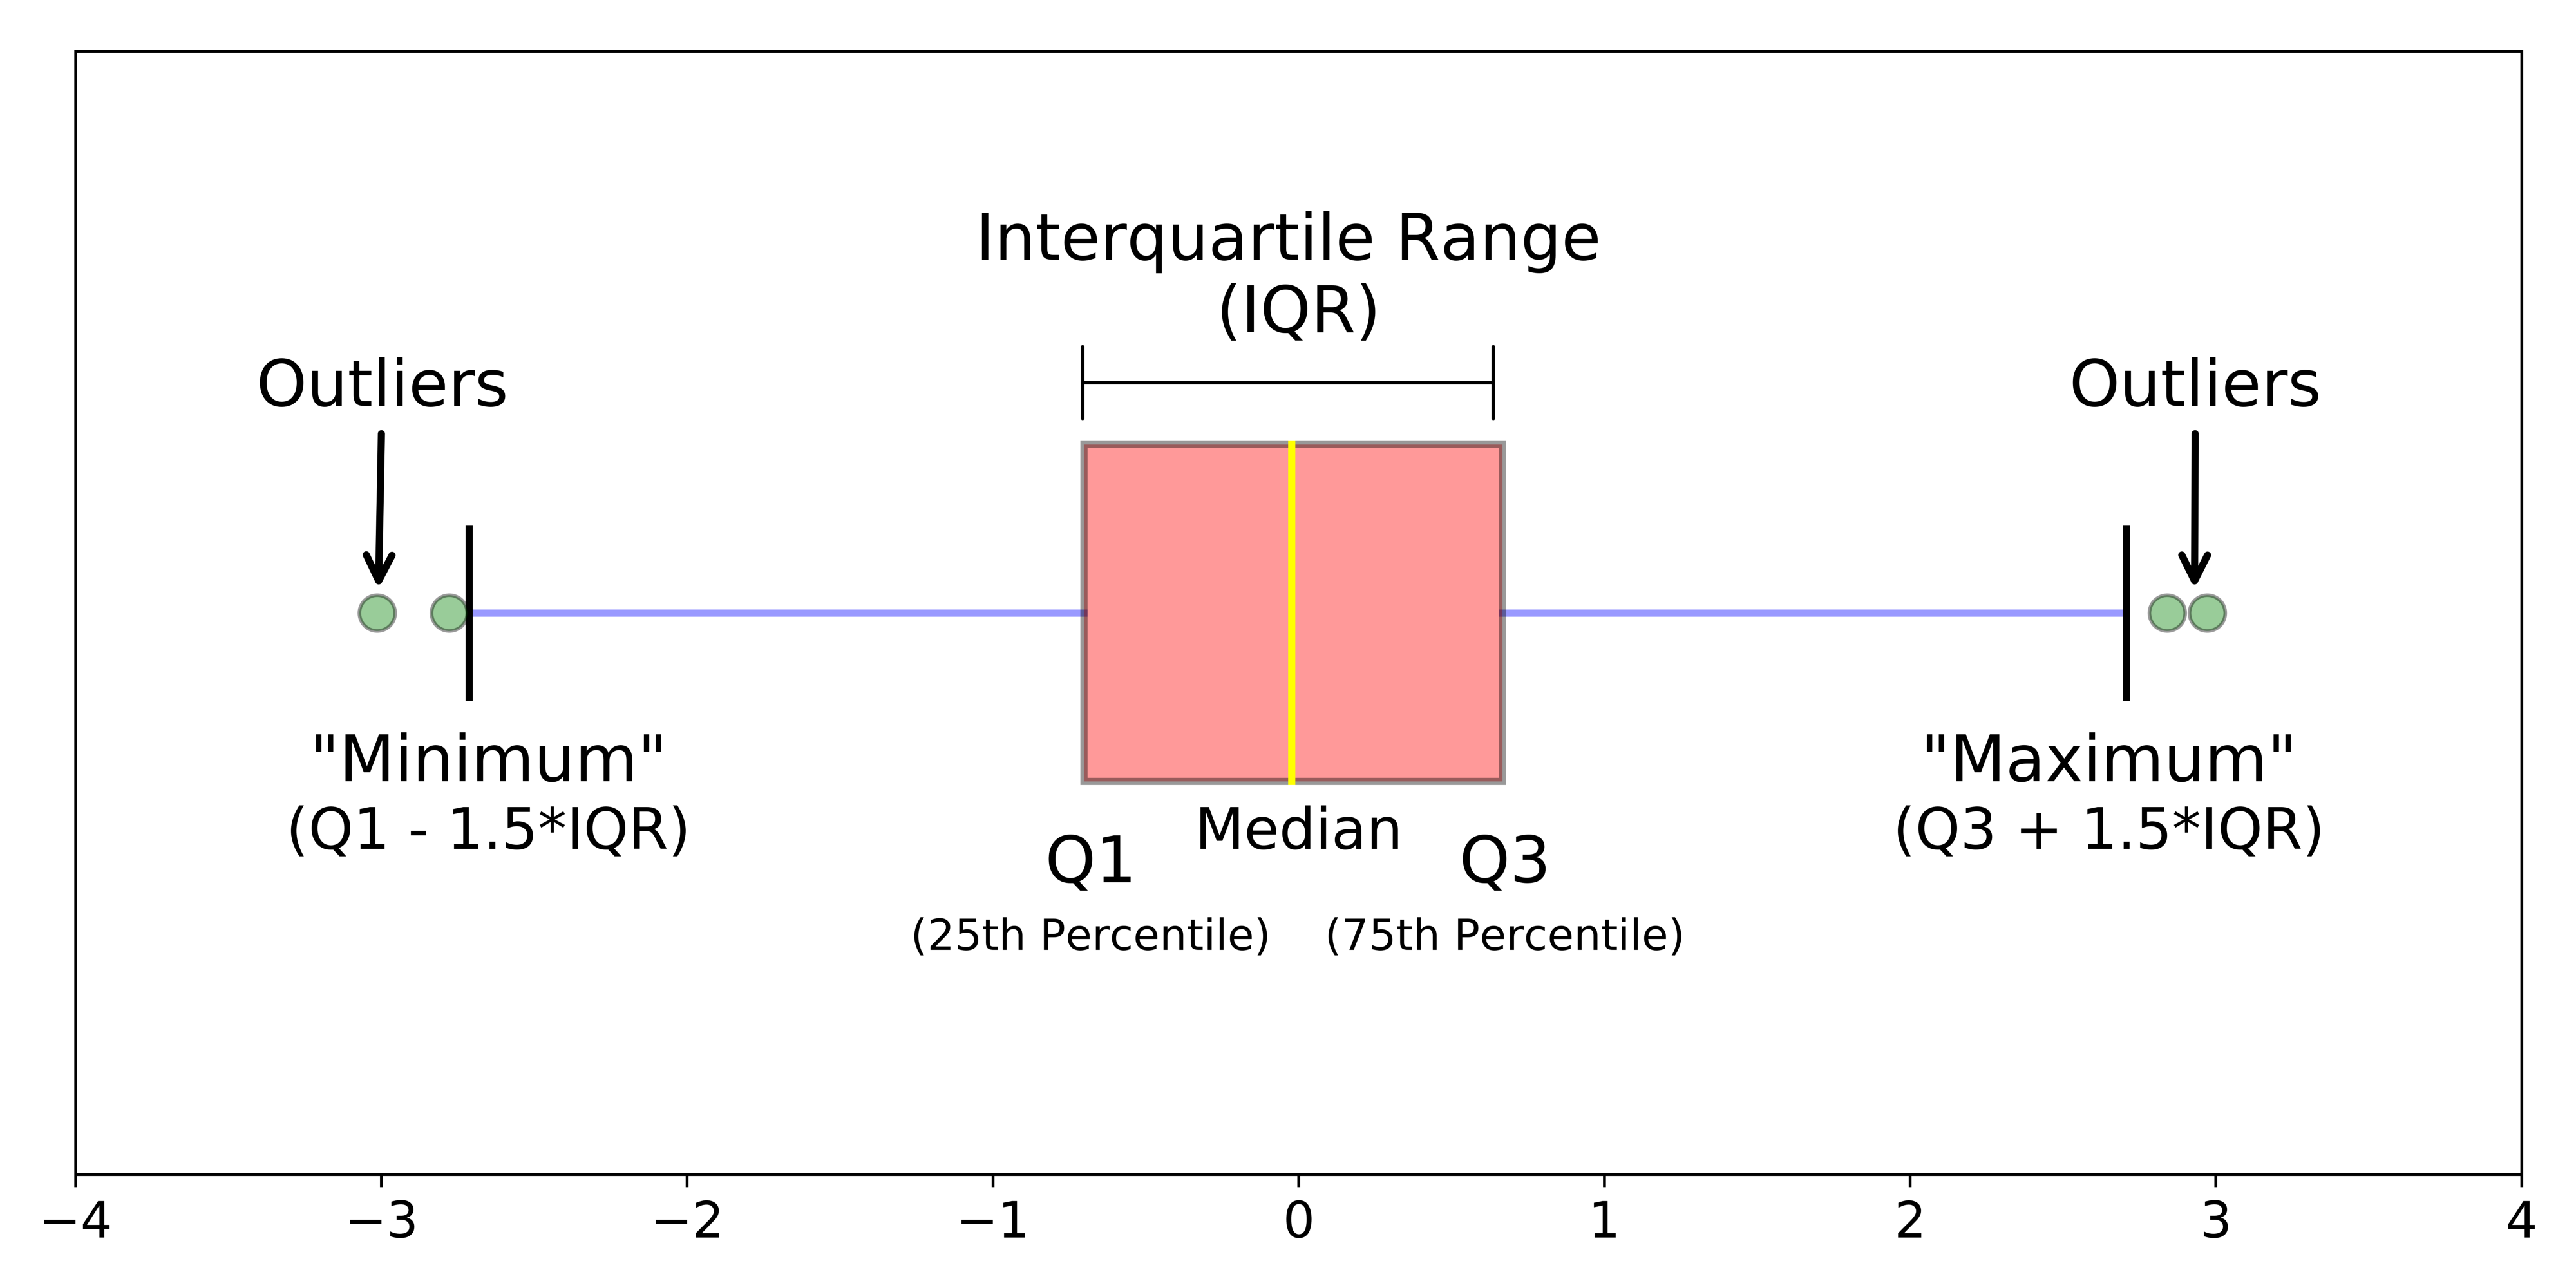

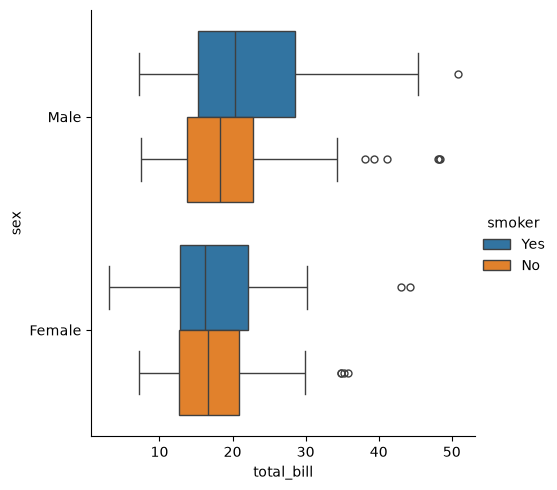

In [28]:
sns.catplot(data=tips,x='total_bill',y='sex',kind='box',hue='smoker')

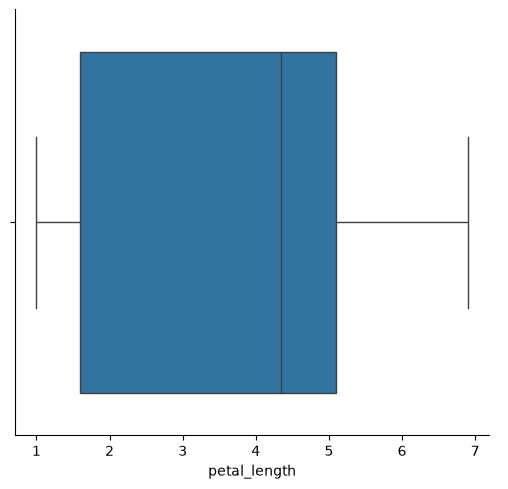

In [29]:
#single boxplot
sns.catplot(data=iris,x='petal_length',kind='box')

#### Violinplot = (Boxplot + KDEplot)

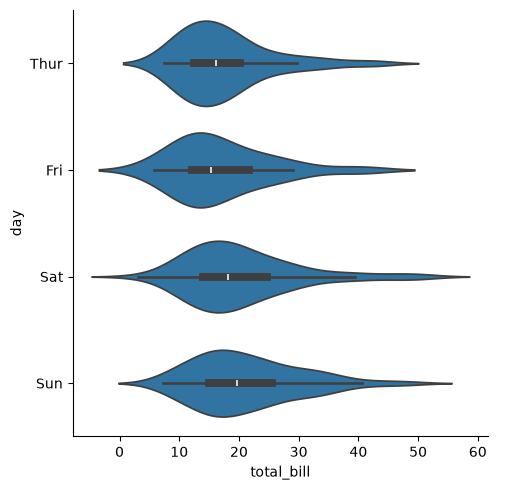

In [30]:
sns.catplot(data=tips,x='total_bill',y='day',kind='violin')

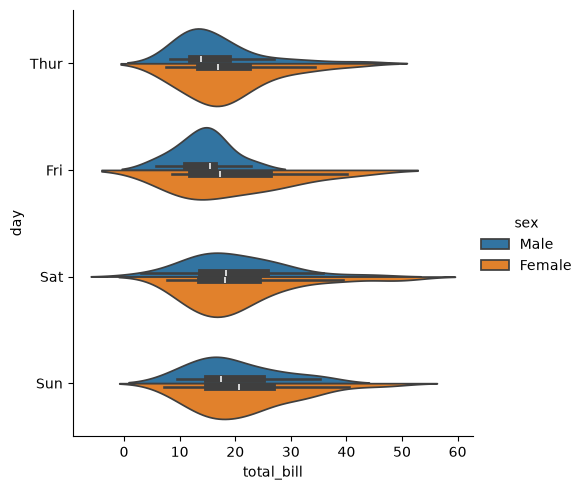

In [31]:
sns.catplot(data=tips,x='total_bill',y='day',kind='violin',hue='sex',split=True) #split will show the distribution side by side

#### Categorical Estimate Plot -> for central tendency

- Barplot
- Pointplot
- Countplot

#### Barplot
Seaborn bar plot represents an estimate of central tendency (by default, the mean) for a numeric variable using the height of rectangular bars, while displaying statistical uncertainty using error bars.When there are multiple observations in each category, it also uses bootstrapping to compute a confidence interval around the estimate, which is plotted using error bars

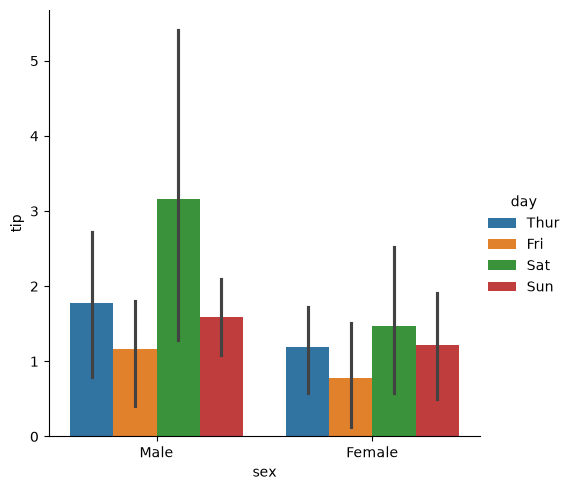

In [32]:
sns.catplot(data=tips,y='tip',x='sex',kind='bar',hue='day',estimator=np.var) #estimator takes the aggregated function to perform on the data

#### Pointplot
A Seaborn pointplot is a specialized statistical visualization tool used to display the point estimate of central tendency (usually the mean) for a numeric variable across different categorical levels.

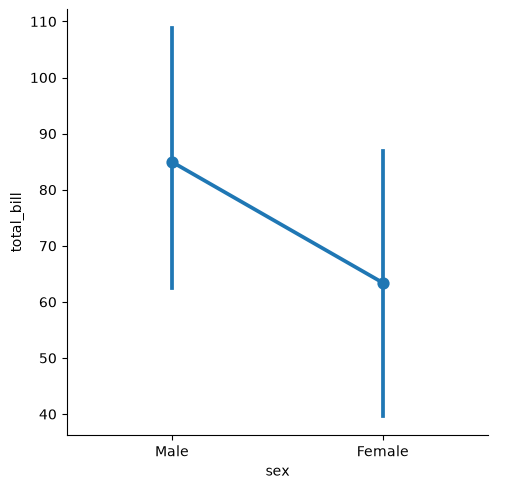

In [33]:
sns.catplot(data=tips,x='sex',y='total_bill',kind='point',estimator=np.var)

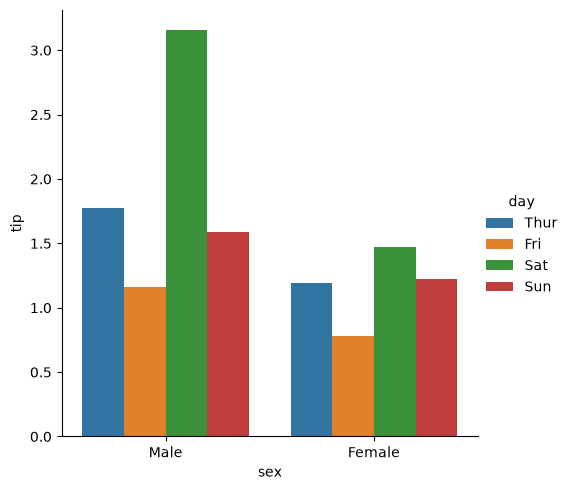

In [34]:
# we can also remove the errorbars by setting errorbar=None
sns.catplot(data=tips,y='tip',x='sex',kind='bar',hue='day',estimator=np.var,errorbar=None)

#### Countplot is the histogram for categorical data and it acts like Pandas' count_value() function

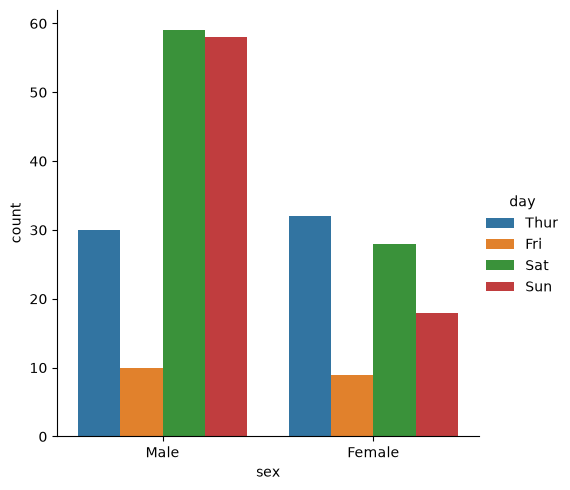

In [35]:
sns.catplot(data=tips,x='sex',kind='count',hue='day')

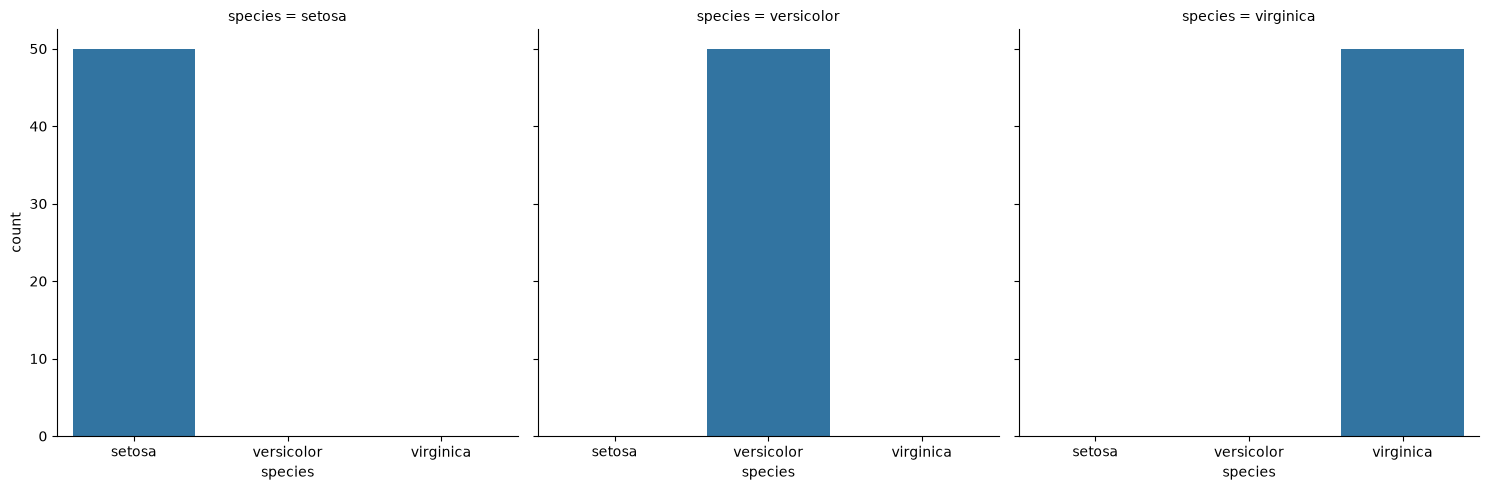

In [36]:
#faceting
sns.catplot(data=iris,x='species',col='species',kind='count')

#### Regression Plots
- Regplot
- Lmplot
- Residplot
  
In the simplest invocation, top two functions draw a scatterplot of two variables, x and y, and then fit the regression model y ~ x and plot the resulting regression line and a 95% confidence interval for that regression.


<Axes: xlabel='total_bill', ylabel='tip'>

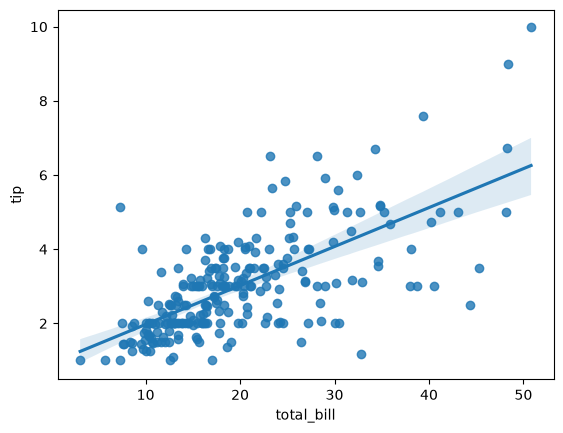

In [37]:
#axis level function and it has no hue parameter
sns.regplot(data=tips,x='total_bill',y='tip')

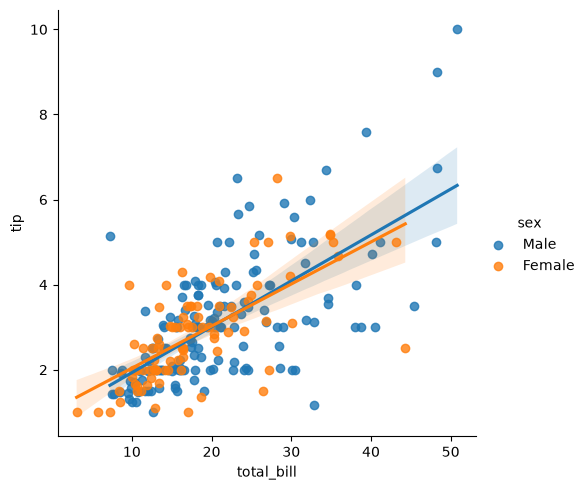

In [38]:
#figure level function
sns.lmplot(data=tips,x='total_bill',y='tip',hue='sex')

#### Residplot
A residplot is a data visualization tool used in linear regression analysis to evaluate a model's fit. It regresses the response variable (y) on the predictor variable (x) and plots the residual values against the predicted values. Ideally, the points should be randomly scattered around a horizontal line at 0.If your residual points form a distinct pattern (like a curve or a megaphone shape), it indicates that your model might violate linear regression assumptions (e.g., you might need to use a polynomial model or transform your variables)

<Axes: xlabel='total_bill', ylabel='tip'>

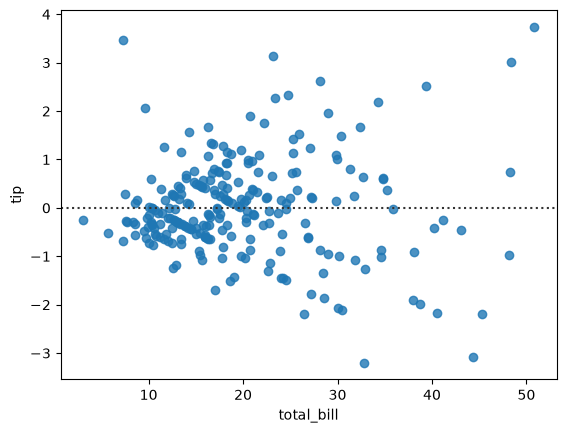

In [39]:
sns.residplot(data=tips,x='total_bill',y='tip')

#### Facetgrids
This is another method for faceting but only for axis level function.

It gives better control

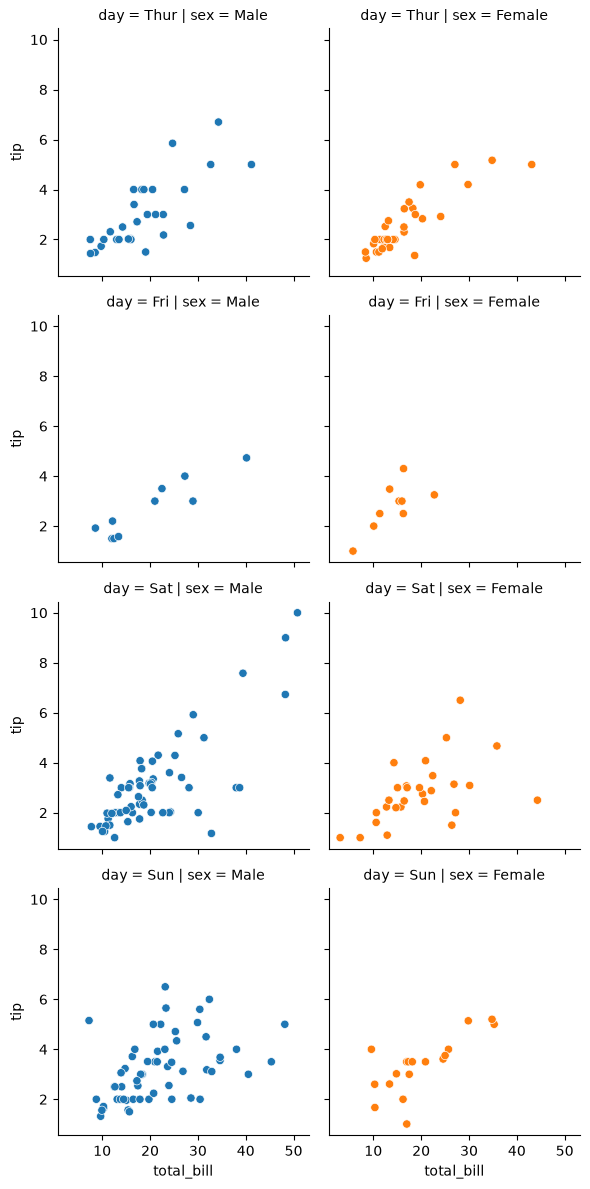

In [40]:
g=sns.FacetGrid(data=tips,col='sex',row='day')
g.map_dataframe(sns.scatterplot, x='total_bill', y='tip',hue='sex')

####  Plotting Pairwise Relationship (PairGrid Vs Pairplot)

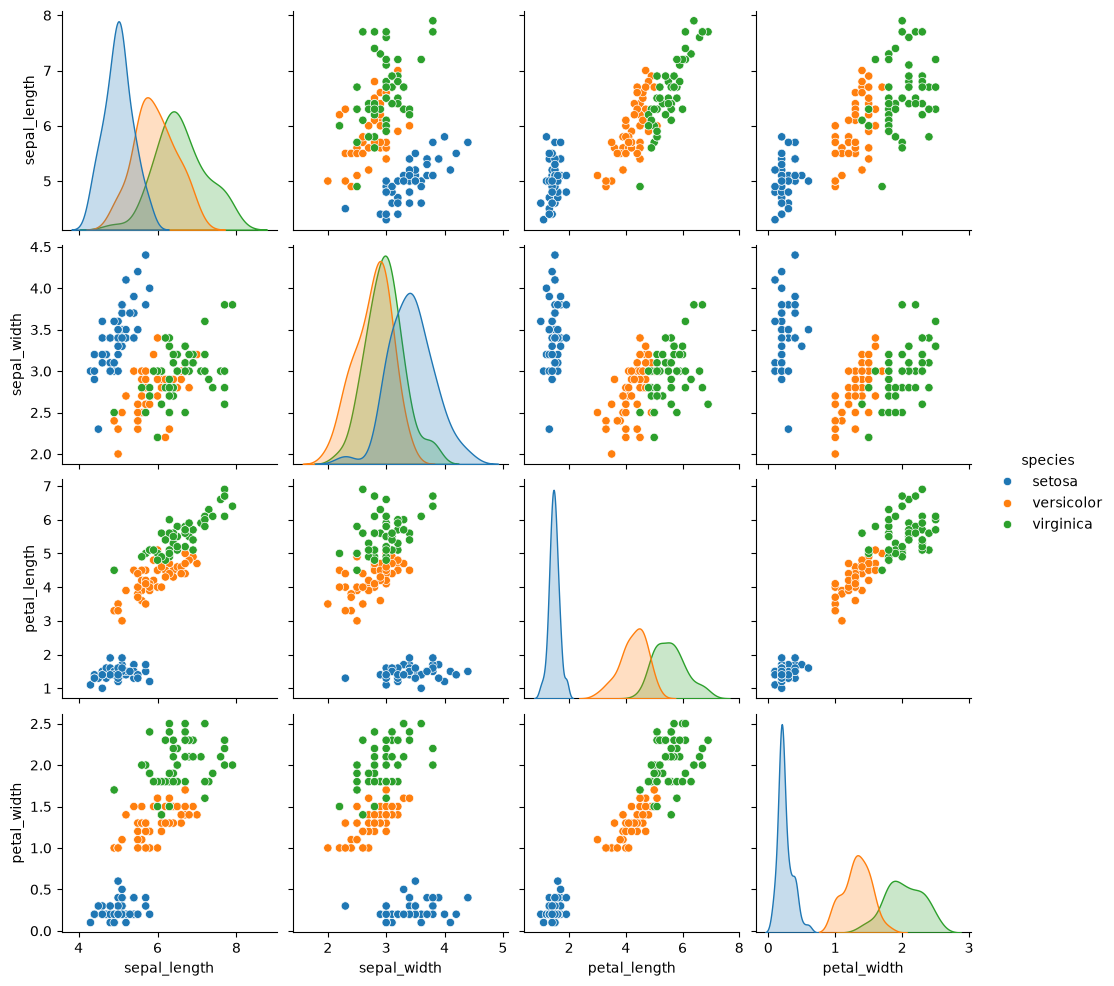

In [41]:
#pair plot will automatically fetch numerical columns from the data and will plot scatterplots on them and displot(hist or kde) on the same colum
sns.pairplot(iris,hue='species')

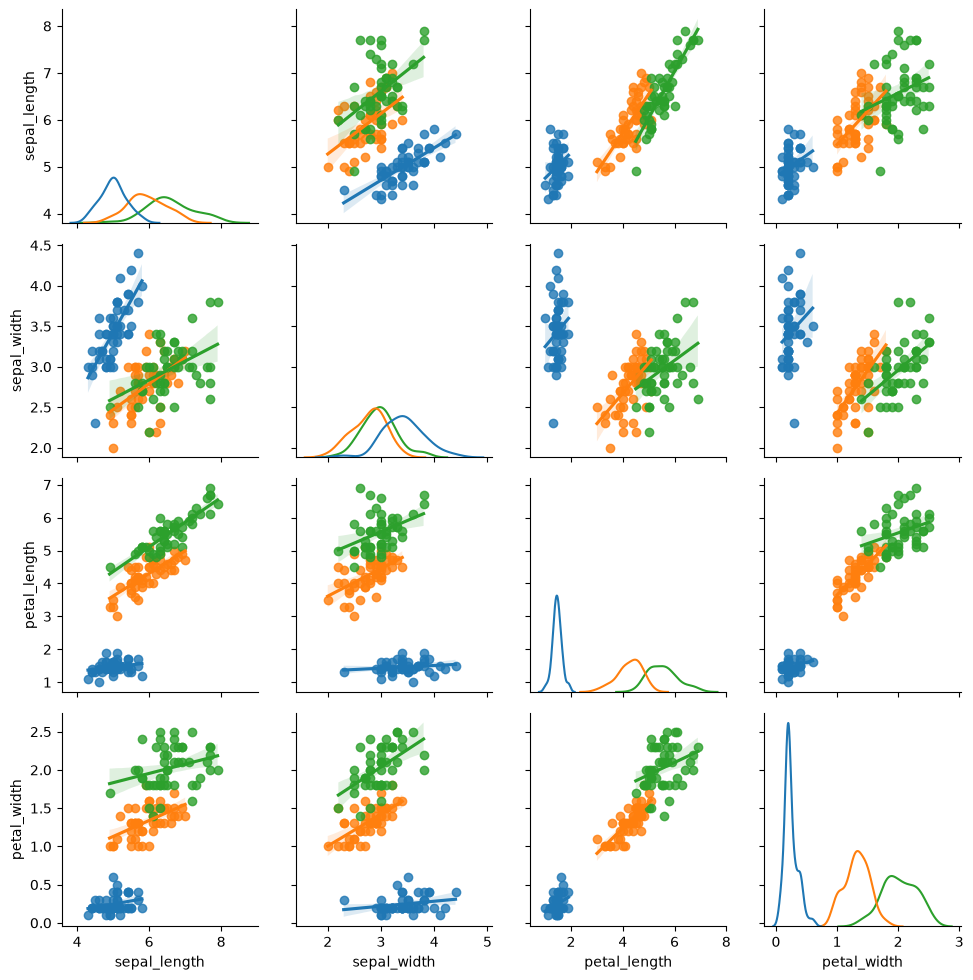

In [42]:
# PairGrid is FacetGrid for Pairplot
g=sns.PairGrid(data=iris,hue='species')
g.map_diag(sns.kdeplot)
g.map_offdiag(sns.regplot)

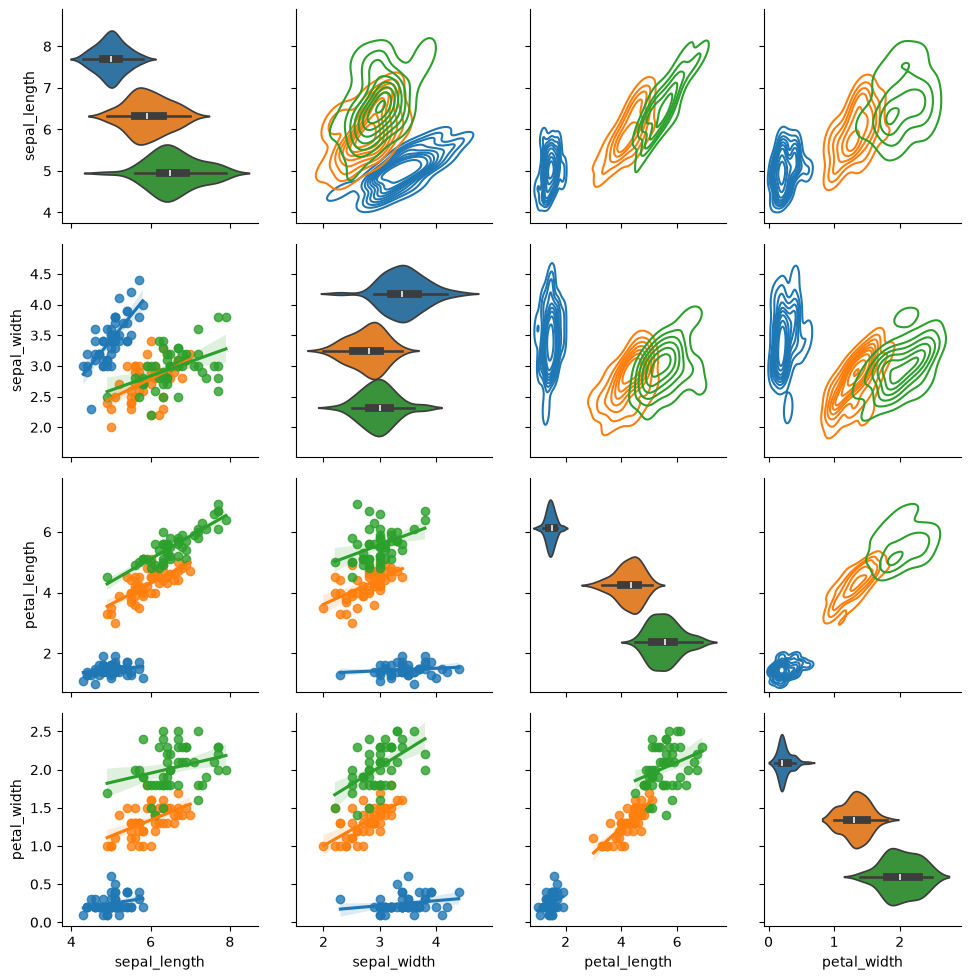

In [43]:
# map_diag -> map_upper -> map_lower
g=sns.PairGrid(data=iris,hue='species')
g.map_upper(sns.kdeplot)
g.map_lower(sns.regplot)
g.map_diag(sns.violinplot)

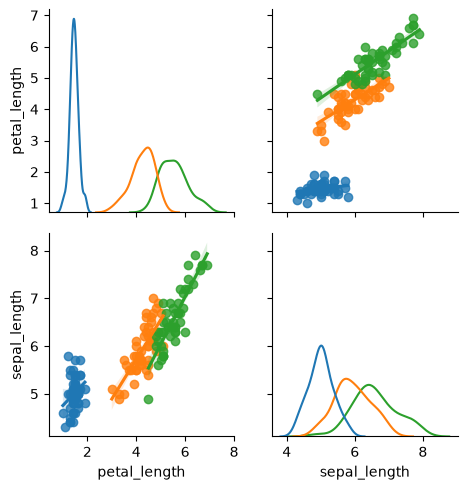

In [44]:
# we can also choose which values should we use for plotting
g=sns.PairGrid(data=iris,hue='species',vars=['petal_length','sepal_length'])
g.map_diag(sns.kdeplot)
g.map_offdiag(sns.regplot)

#### Jointplot
This function creates a multi-panel figure that displays the bivariate relationship between two variables in the center plot, alongside their individual univariate distributions in the top and right margins. It is an efficient, single-line tool for simultaneously analyzing correlation and distribution

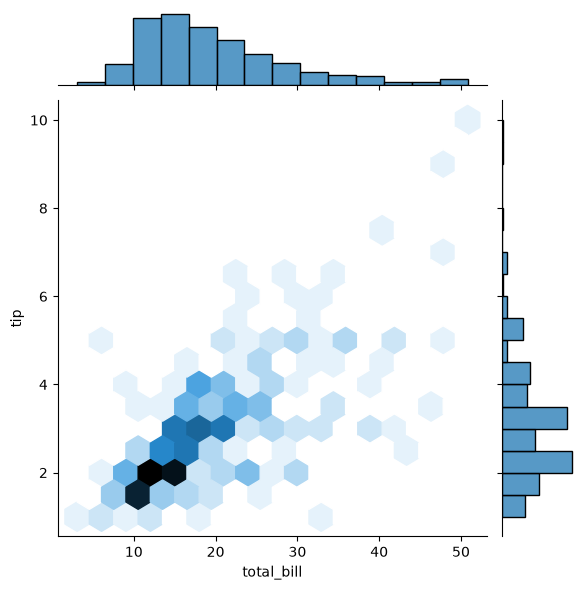

In [57]:
sns.jointplot(data=tips,x="total_bill",y='tip',kind='hex')

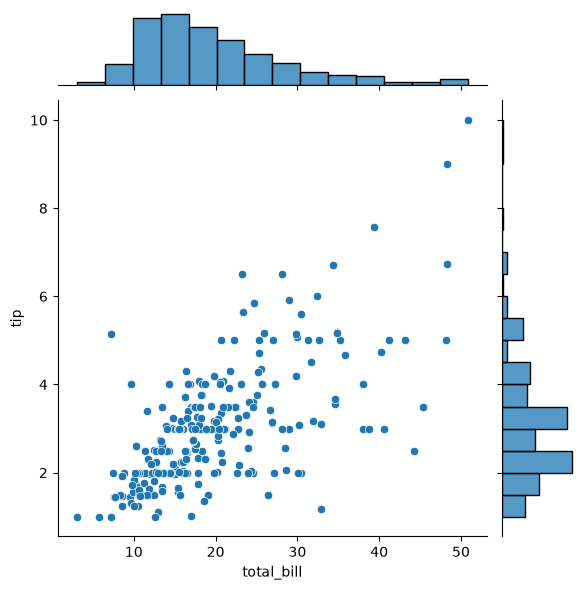

In [58]:
sns.jointplot(data=tips,x='total_bill',y='tip')

#### Jointgrid
It is just like PairGrid for Jointplot (It gives more control)

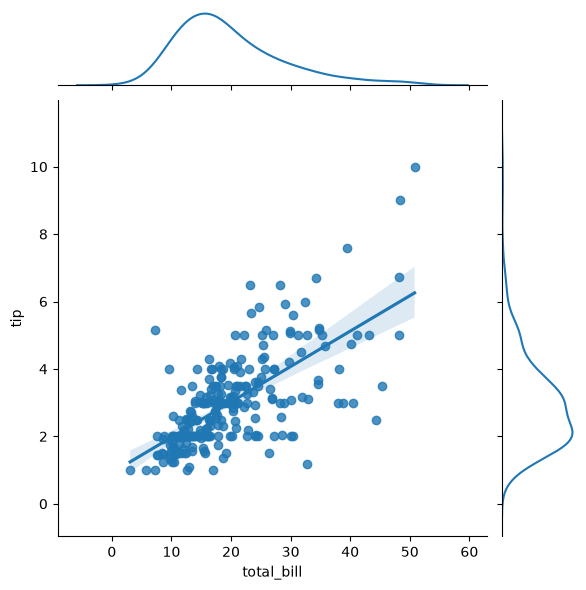

In [55]:
g=sns.JointGrid(data=tips,x='total_bill',y='tip')
g.plot(sns.regplot,sns.kdeplot) #first plot is for bivariate and second for univariate